# Crash!💥 Boom!💥 Bang! 💥🚗🚙💥🚗
**A SQL based exploratory data analysis of traffic accidents in Okinawa, Japan**

---   
# <span style="color:#0279f0;">Part 5: Categorical Analysis</span>
---

We know where and when accidents happened. Now let's look at what kind of accidents they were, who was involved, and what the conditions were like.

**Analysis Tasks**
1. **Accident Types** – Compare the most common types and how often they were fatal.
2. **Age Groups** – Check which age groups appear most often for Party A and Party B.
3. **Weather & Road Surface** – See what conditions were recorded at the time of the crash.

**Tools used in this notebook**
- Pandas – for loading the CSV.
- DuckDB – for decoding categories and aggregating counts.
- Matplotlib / Seaborn – for visualisations.

📖 **Code reference** [National Police Agency 2024 codebook (PDF)](https://www.npa.go.jp/publications/statistics/koutsuu/opendata/2024/codebook_2024.pdf)

##### 👩🏻‍💻 *<span style="color:#0279f0">Loading data to begin...</span>*

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from sql.code_labels import CRASH_TYPES, code_label
from sql.notebook_setup import create_connection, load_data, print_summary, register_table

# Load data with pandas
accidents_df = load_data(project_root / "data" / "okinawa_2024_accidents.csv")

# Connect to DuckDB and register the accidents table
conn = create_connection()
register_table(conn, "accidents", accidents_df)
print_summary(accidents_df, "Accidents Table", max_cols=10)


import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


✅ Accidents Table: 2,749 records
----------------------------------------
✅ Showing 10 of 68 columns:
 1. data_category
 2. prefecture_code
 3. police_station_code
 4. report_id
 5. accident_details_code
 6. fatalities
 7. injured_persons
 8. route_code
 9. location_code
10. municipality_code
... 58 additional columns


---
### **5.1 Accident Types**
Which types made up most of the accidents? Which types accounted for the most fatal crashes?

##### 👩🏻‍💻 *<span style="color:#0279f0">SQL: Analysing Accident Types...</span>*

,accident_type_code,accident_type,accident_count,fatal_crashes,fatalities,pct_of_all_accidents,fatal_crash_pct
0,21,Vehicle–vehicle,2217,11,11.0,80.65,0.50
1,1,Pedestrian–vehicle,469,17,18.0,17.06,3.62
2,41,Single vehicle,63,15,15.0,2.29,23.81


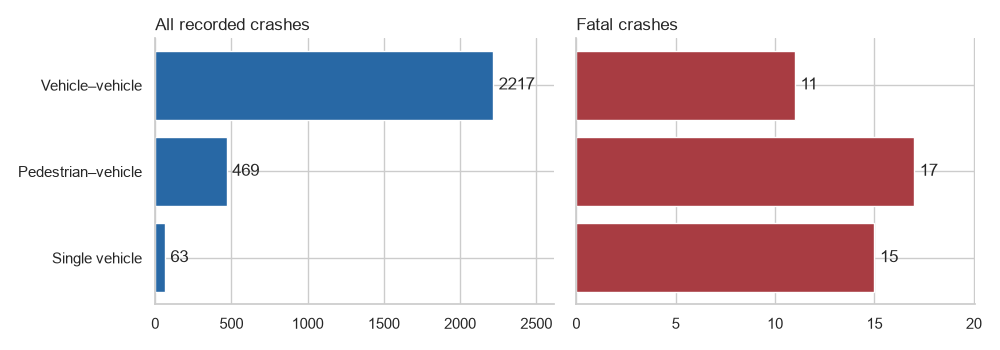

In [2]:
# ========================================
# Accident counts and severity by type
# ========================================
query_types = f"""
SELECT
    accident_type_code,
    {code_label("accident_type_code", CRASH_TYPES)} AS accident_type,
    COUNT(*) AS accident_count,
    COUNT(*) FILTER (WHERE accident_details_code = 1) AS fatal_crashes,
    SUM(fatalities) AS fatalities,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS pct_of_all_accidents,
    ROUND(COUNT(*) FILTER (WHERE accident_details_code = 1) * 100.0 / COUNT(*), 2)
        AS fatal_crash_pct
FROM accidents
GROUP BY ALL
ORDER BY accident_count DESC
"""
results_types = conn.execute(query_types).fetchdf()
display(results_types)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
ax1.barh(results_types["accident_type"], results_types["accident_count"], color="#2868a5")
ax2.barh(results_types["accident_type"], results_types["fatal_crashes"], color="#a83c42")
ax1.invert_yaxis()
ax1.set_title("All recorded crashes", loc="left")
ax2.set_title("Fatal crashes", loc="left")
for ax in (ax1, ax2):
    ax.bar_label(ax.containers[0], fmt="%g", padding=4)
    ax.margins(x=0.18)
sns.despine()
plt.tight_layout()
plt.show()

### 📊 <span style="color:orange;">5.1 Key Findings</span>

- **Vehicle–vehicle** crashes were the most common, with **2,217 crashes (80.65%)**.
- **Pedestrian–vehicle** crashes accounted for **17 of the 43 fatal crashes**, the most of any type.
- **Single-vehicle** crashes accounted for only **63 crashes**, but **15 were fatal (23.81%)**. The group is small, so a few crashes can shift that percentage.
- The fatal share tells us how often a *recorded crash* in that group was fatal. Coverage is limited to casualty crashes. Pedestrian and vehicle-only incidents have different chances of entering that dataset. Comparing road risk would also require exposure measures such as trips, distance travelled or pedestrian crossings.

---
### **5.2 Age Groups**
Which age bands appear most often in each of the two recorded party fields?

##### 👩🏻‍💻 *<span style="color:#0279f0">SQL: Analysing Age Groups...</span>*

,party,road_user,age_code,age_group,party_records,pct_of_party_records
0,Party A,Pedestrian,1,0–24,4,57.14
1,Party A,Motor vehicle,1,0–24,446,16.39
2,Party A,Cycle or other light vehicle,1,0–24,12,57.14
3,Party B,Cycle or other light vehicle,1,0–24,101,54.01
4,Party B,Motor vehicle,1,0–24,402,20.06
5,Party B,Pedestrian,1,0–24,112,24.24
6,Party A,Motor vehicle,25,25–34,488,17.93
7,Party A,Cycle or other light vehicle,25,25–34,3,14.29
8,Party A,Pedestrian,25,25–34,2,28.57
9,Party B,Cycle or other light vehicle,25,25–34,13,6.95


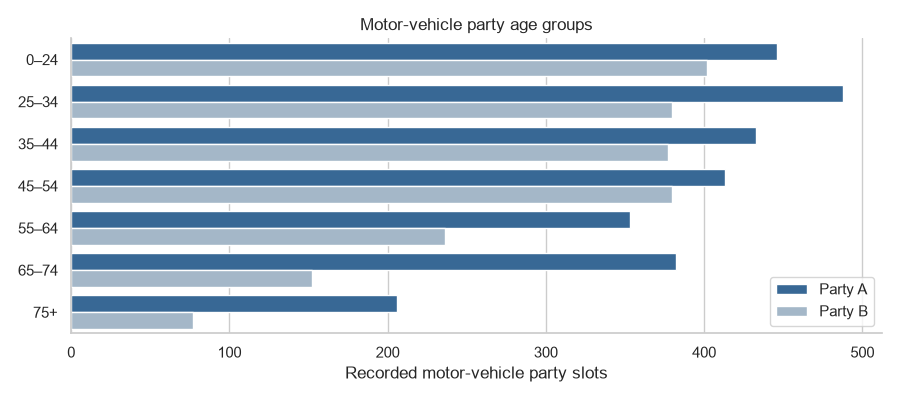

In [3]:
# ========================================
# Stack the two recorded party slots
# ========================================
query_age = """
WITH parties AS (
    SELECT 'Party A' AS party, age_party_a AS age_code, party_type_code_party_a AS party_type
    FROM accidents
    UNION ALL
    SELECT 'Party B' AS party, age_party_b AS age_code, party_type_code_party_b AS party_type
    FROM accidents
)
SELECT
    party,
    CASE
        WHEN party_type BETWEEN 1 AND 39 OR party_type = 43 THEN 'Motor vehicle'
        WHEN party_type IN (51, 52, 59) THEN 'Cycle or other light vehicle'
        WHEN party_type = 61 THEN 'Pedestrian'
        ELSE 'Other or unknown'
    END AS road_user,
    age_code,
    CASE age_code
        WHEN 0 THEN 'Unknown / no other party'
        WHEN 1 THEN '0–24'
        WHEN 25 THEN '25–34'
        WHEN 35 THEN '35–44'
        WHEN 45 THEN '45–54'
        WHEN 55 THEN '55–64'
        WHEN 65 THEN '65–74'
        WHEN 75 THEN '75+'
        ELSE 'Unmapped code'
    END AS age_group,
    COUNT(*) AS party_records,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (PARTITION BY party, road_user), 2)
        AS pct_of_party_records
FROM parties
GROUP BY party, road_user, age_code
ORDER BY CASE WHEN age_code = 0 THEN 99 ELSE age_code END, party
"""
results_age = conn.execute(query_age).fetchdf()
display(results_age)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(
    data=results_age.loc[results_age["road_user"].eq("Motor vehicle")], y="age_group", x="party_records", hue="party",
    palette=["#2868a5", "#9eb7ce"], ax=ax
)
ax.set(xlabel="Recorded motor-vehicle party slots", ylabel="", title="Motor-vehicle party age groups")
ax.legend(title=None)
sns.despine()
plt.tight_layout()
plt.show()

### 📊 5.2 Key Findings

- The table groups each party slot by road-user type. The chart uses motor-vehicle parties. The two slots are roles in the crash record, and a crash can contribute to both. The NPA gives first-party status to the party with greater fault, with lesser injury breaking a tie. The age bands cover different numbers of years. [NPA terminology](https://www.npa.go.jp/publications/statistics/koutsuu/yougo.html)
- Of the 96 Party B age-zero entries, 33 were unidentified parties, 45 represented objects or similar, and 18 had no counterpart.

---
### **5.3 Weather & Road Surface**
What were the conditions at the time of the crash?

##### 👩🏻‍💻 *<span style="color:#0279f0">SQL: Analysing Weather & Road Surface...</span>*

,category,condition,accident_count,fatal_crashes,fatal_crash_pct,pct_of_all_accidents
0,Weather,Clear,1643,27,1.64,59.77
1,Weather,Cloudy,659,12,1.82,23.97
2,Weather,Rain,447,4,0.89,16.26
3,Road surface,Dry pavement,2183,37,1.69,79.41
4,Road surface,Wet pavement,564,6,1.06,20.52
5,Road surface,Unpaved,2,0,0.00,0.07


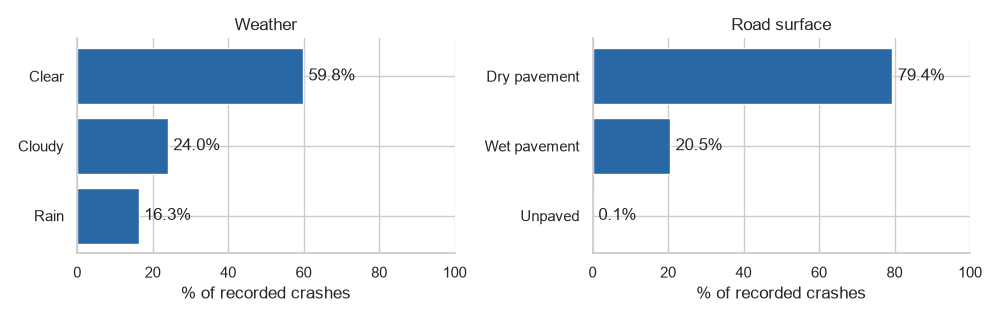

,weather,surface,accident_count,fatal_crashes,fatal_crash_pct
0,Clear,Dry pavement,1626,27,1.66
1,Cloudy,Dry pavement,556,10,1.80
2,Rain,Wet pavement,446,4,0.90
3,Cloudy,Wet pavement,102,2,1.96
4,Clear,Wet pavement,16,0,0.00
5,Cloudy,Unpaved,1,0,0.00
6,Clear,Unpaved,1,0,0.00
7,Rain,Dry pavement,1,0,0.00


In [4]:
# ========================================
# Keep weather and surface denominators separate
# ========================================
conn.execute("""
CREATE OR REPLACE TEMP VIEW crash_conditions AS
SELECT accident_details_code,
    CASE weather_code
            WHEN 1 THEN 'Clear'
            WHEN 2 THEN 'Cloudy'
            WHEN 3 THEN 'Rain'
            WHEN 4 THEN 'Fog'
            WHEN 5 THEN 'Snow'
            ELSE 'Unmapped code'
        END AS weather,
    CASE road_condition_code
            WHEN 1 THEN 'Dry pavement'
            WHEN 2 THEN 'Wet pavement'
            WHEN 3 THEN 'Icy pavement'
            WHEN 4 THEN 'Snow-covered pavement'
            WHEN 5 THEN 'Unpaved'
            ELSE 'Unmapped code'
        END AS surface
FROM accidents
""")

query_conditions = """
WITH conditions AS (
    SELECT
        'Weather' AS category,
        weather AS condition,
        accident_details_code
    FROM crash_conditions
    UNION ALL
    SELECT
        'Road surface' AS category,
        surface AS condition,
        accident_details_code
    FROM crash_conditions
)
SELECT
    category,
    condition,
    COUNT(*) AS accident_count,
    COUNT(*) FILTER (WHERE accident_details_code = 1) AS fatal_crashes,
    ROUND(100.0 * COUNT(*) FILTER (WHERE accident_details_code = 1) / COUNT(*), 2)
        AS fatal_crash_pct,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (PARTITION BY category), 2)
        AS pct_of_all_accidents
FROM conditions
GROUP BY category, condition
ORDER BY category DESC, accident_count DESC
"""
results_conditions = conn.execute(query_conditions).fetchdf()
display(results_conditions)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharex=True)
for ax, (category, rows) in zip(axes, results_conditions.groupby("category", sort=False)):
    bars = ax.barh(rows["condition"], rows["pct_of_all_accidents"], color="#2868a5")
    ax.invert_yaxis()
    ax.set(xlim=(0, 100), xlabel="% of recorded crashes", title=category)
    ax.bar_label(bars, fmt="%.1f%%", padding=4)
sns.despine()
plt.tight_layout()
plt.show()

display(conn.execute("""
SELECT weather, surface, COUNT(*) AS accident_count,
    COUNT(*) FILTER (WHERE accident_details_code = 1) AS fatal_crashes,
    ROUND(100.0 * COUNT(*) FILTER (WHERE accident_details_code = 1) / COUNT(*), 2)
        AS fatal_crash_pct
FROM crash_conditions
GROUP BY weather, surface
ORDER BY accident_count DESC
""").fetchdf())

### 📊 <span style="color:orange;">5.3 Key Findings</span>

- Most crashes were recorded in **clear weather** (1,643) and on **dry pavement** (2,183). These are two separate totals.
- **447 crashes** were recorded in rain and **564** on wet pavement. Of the rain crashes, 446 were on wet pavement and four of those were fatal (0.90%). Another 118 wet-pavement crashes occurred in clear or cloudy weather, and two were fatal (1.69%).
- How much driving took place in each condition? We would need that information before comparing road risk across weather or surface groups.

---
## 📊 What's Next?
In Part 6, we'll put the findings together and look at what Okinawa could investigate first.